In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
# import fastplotlib as fpl
import scipy
from scipy import linalg
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib.colors import LogNorm
import fastplotlib as fpl
import tifffile
from skophys.viz_helpers import spatial_to_rgba
from skophys.datasets import ARProcess, ARProcessMovie
from tifffile.tifffile import imwrite

from caiman.paths import caiman_datadir

%matplotlib inline

/opt/anaconda3/envs/mescore/lib/python3.11/site-packages/pygfx/utils/_dirs.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


In [2]:
def remove_duplicate_rows(matrix):
    matrix = np.array(matrix)
    unique_matrix = np.unique(matrix, axis=1)
    return unique_matrix

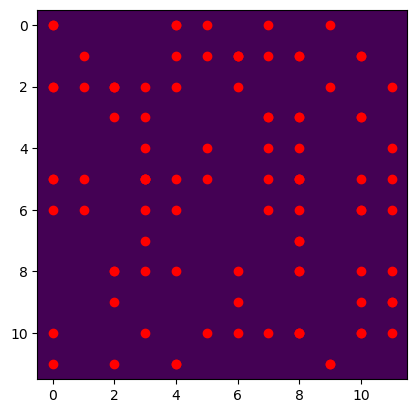

In [3]:
fig_label = "twolag"

# use_centering = True
use_centering = False
use_whitening = True
# use_whitening = False
denoise_diagonal = True
# denoise_diagonal = False
# use_eco_whitening = True
use_eco_whitening = False

n_lags = 2
lag_time = 1

simulation = True
obs_noise_level = 0.3
fp = 0.005
# fp = 0.0005

dims = 12, 12
source_size = 1
n_sources = 10
np.random.seed(3)
locs = (np.random.rand(100, 2) * dims[0]).clip(0).astype(int)
locs = remove_duplicate_rows(locs)

# dims = 20, 20
# source_size = 2
# n_sources = 2
# locs = (np.random.rand(2, 2) * dims[0]).clip(0).astype(int)
# # locs[0,0] = 6
# # locs[0,1] = 10
# # locs[1,0] = 14
# # locs[1,1] = 10
# locs[0,0] = 9
# locs[0,1] = 10
# locs[1,0] = 10
# locs[1,1] = 10

plt.imshow(np.zeros(dims))
plt.scatter(locs[:, 0], locs[:, 1], c="r")
plt.show()

simulation = False
n_sources = 15
# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/demoMovie.tif"
path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/dendrites_rect.tif"


r.shape = (6,)
z.shape = (6, 6)
spatial_footprints.shape = (15, 12, 12)
added_source = 15


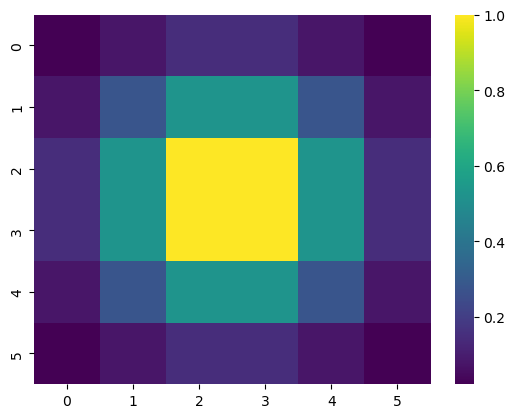

In [4]:
# S = ARProcessMovie(
#     n_timepoints=1_000,
#     n_components=n_sources,
#     ar_noise_sigma=0.1,
#     obs_noise_sigma=obs_noise_level,
#     movie_dims=dims,
#     component_size=source_size,
#     component_locs=locs,
# )

S = ARProcessMovie(
    n_timepoints=2_000,
    n_components=n_sources,
    ar_noise_sigma=0.1,
    obs_noise_sigma=obs_noise_level,
    movie_dims=dims,
    component_size=source_size,
    component_locs=locs,
    decay_constant = 0.6,
    # baselines=[1, 1],
    firing_probability=fp,
)

sns.heatmap(S.kernel, cmap="viridis")

fname = os.path.join(caiman_datadir(), 'example_movies', '/Users/rshang/Work/caiman/mesmerize-core/exp_data/ToySim2D.tif')
imwrite(fname, S.movie)

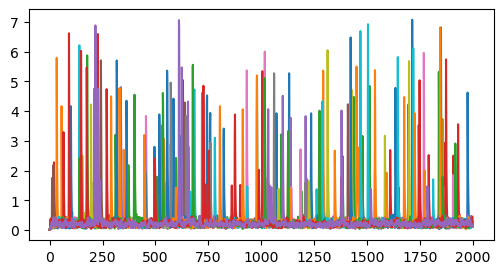

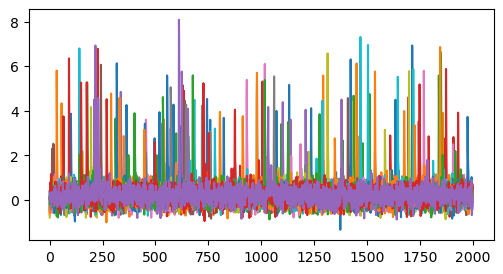

In [5]:
traces = S.traces
traces_obs = S.traces_obs

fig, ax = plt.subplots(figsize=(6, 3))
for src in range(0,len(traces)):
    ax.plot(traces[src])
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/truth_trace_{fig_label}.png')
plt.show()

fig, ax = plt.subplots(figsize=(6, 3))
for src in range(0,len(traces_obs)):
    ax.plot(traces_obs[src])
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/observed_trace_{fig_label}.png')
plt.show()

In [6]:
source_footprints = S.source_footprints
# source_footprints = S.source_footprints[:, ::2, ::2]
print (f"source_footprints.shape = {source_footprints.shape}")

source_footprints.shape = (15, 12, 12)


In [7]:
movie = S.movie
# Convert the data type to float32
movie = movie.astype(np.float32)
# movie = movie.astype(np.float32)[:, ::2, ::2]
print (movie.shape)

(2000, 12, 12)


In [8]:
if not simulation:

    # movie = tifffile.imread(path)[:]
    # movie = tifffile.imread(path)[:, ::2, ::2]
    # movie = tifffile.imread(path)[:2000, :, :]
    movie = tifffile.imread(path)[:2000, ::2, ::2]

    # Convert the data type to float32
    movie = movie.astype(np.float32)
    
    # n_pix_x = movie.shape[2]
    # n_pix_y = movie.shape[1]
    # n_frame = movie.shape[0]
    
    # n_pix_x_small = int(n_pix_x/3.)
    # n_pix_y_small = int(n_pix_y/3.)
    # small_movie = movie[:, n_pix_y_small:2*n_pix_y_small, n_pix_x_small:2*n_pix_x_small]
    
    # # Convert the data type to float32
    # movie = small_movie.astype(np.float32)
    
    print (movie.shape)

(2000, 28, 27)


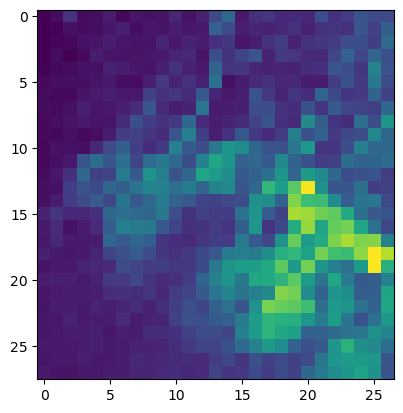

In [9]:
# fpl.ImageWidget(movie).show()

plt.imshow(movie.mean(axis=0))
if simulation:
    truth_levels = [0.60]
    for src in range(0,n_sources):
        plt.contour(source_footprints[src], levels=truth_levels, colors='r')
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/data_image_{fig_label}.png')

In [10]:
from skophys.preprocessing import UnVectorizer, Vectorizer

unvec = UnVectorizer(movie.shape[1:])
vectorizer = Vectorizer()
X = vectorizer.fit_transform(movie)

/opt/anaconda3/envs/mescore/lib/python3.11/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


X.shape = (756, 2000)
P.shape = (3, 756, 1998)


<Axes: >

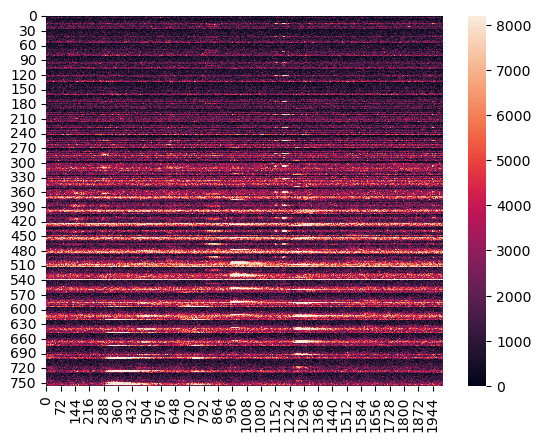

In [11]:
n_pixels = X.shape[0]
n_time_steps = X.shape[1]

P = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
for lag in range(0,n_lags+1):
    for col in range(0,n_time_steps-n_lags*lag_time):
        P[lag,:,col] = X[:,col+lag*lag_time]

print (f"X.shape = {X.shape}")
print (f"P.shape = {P.shape}")
sns.heatmap(P[n_lags,:, :])

In [12]:
def eigen_decomposition(M):
    # output eigenvalues and eigenvectors sorted by eigenvalues
    
    eigenvalues, eigenvectors = np.linalg.eig(M)
    eigenvalues = np.real(eigenvalues)
    eigenvectors = np.real(eigenvectors)
    
    sorted_indices = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[sorted_indices]
    eigenvectors = eigenvectors[:, sorted_indices]
    print (f"eigenvectors.shape = {eigenvectors.shape}")

    return eigenvalues, eigenvectors

In [13]:
def covariance_matrix(X):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples
    
    T = X.shape[1]
    COV = X @ X.T / float(T)
    
    return COV

def similarity_matrix(X):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples
    
    N = X.shape[0]
    COV = X.T @ X / float(N)
    
    return COV

In [14]:
def centered_matrix(X):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples
    
    X_mean = X.mean(axis=1, keepdims=True) # has a shape of T x 1

    return X - X_mean

def whitened_matrix(X, X0):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    # COV shape = (N, N)
    COV = covariance_matrix(X0)
    S, U = eigen_decomposition(COV)

    # Epsilon is added to the eigenvalues to prevent division by zero
    epsilon = 1e-5
    inv_sqrt_S = np.diag(1.0 / np.sqrt(S + epsilon))

    # whitening matrix W shape (N, N)
    W = U @ inv_sqrt_S @ U.T

    # whitened data shape (N, T)
    Xw = W @ X

    return Xw

def eco_whitened_matrix(X, X0, k):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    print (f"X.shape = {X.shape}")

    U, S, VT = np.linalg.svd(X0, full_matrices=False)
    S_eco = S[:k]
    U_eco = U[:, :k]
    VT_eco = VT[:k, :]

    # Epsilon is added to the eigenvalues to prevent division by zero
    epsilon = 1e-5
    inv_S = np.diag(1.0 / (S_eco + epsilon))

    print (f"inv_S.shape = {inv_S.shape}")

    # Create a zero matrix of shape (k, num_extra_cols)
    num_extra_cols = X.shape[0] - k
    zeros = np.zeros((k, num_extra_cols))
    
    inv_S_reshape = np.hstack((inv_S, zeros))

    print (f"inv_S_reshape.shape = {inv_S_reshape.shape}")

    # whitening matrix W shape (N, N)
    W = inv_S_reshape @ U.T

    print (f"W.shape = {W.shape}")

    # whitened data shape (N, T)
    Xw = W @ X

    return Xw


eigenvectors.shape = (1998, 1998)


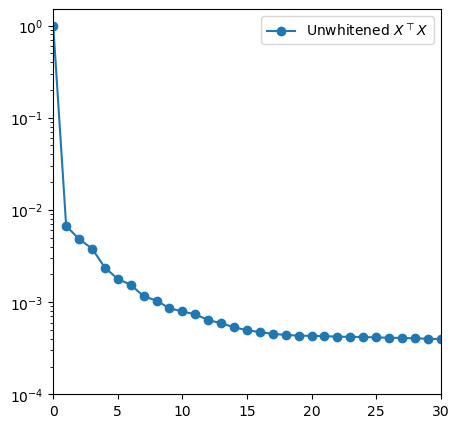

In [15]:
S_PTP, U_PTP = eigen_decomposition(P[0].T @ P[0])

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(S_PTP[:] / S_PTP.max(),'o-', label="Unwhitened $X^{\\top}X$")
ax.legend()
ax.set_yscale('log')
plt.ylim(0.0001, 1.5)
plt.xlim(0, 30)
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/XTX_spectrum_src{src}_{fig_label}.png')
plt.show()

[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


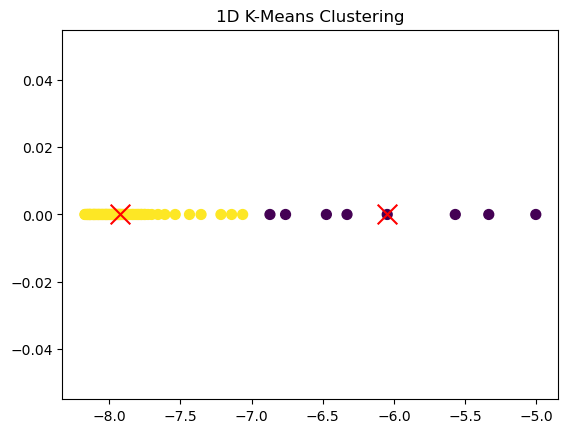

n_sources_kmeans = 9
k = 9


In [16]:
def kmeans_1d(data, k, max_iters=100, tol=1e-4):
    # Randomly initialize k cluster centers
    centroids = np.random.choice(data, k, replace=False)
    centroids[0] = np.max(data)
    for entry in range(1,k):
        centroids[entry] = np.min(data)

    for _ in range(max_iters):
        # Assign each point to the nearest centroid
        distances = np.abs(data[:, np.newaxis] - centroids[np.newaxis, :])
        labels = np.argmin(distances, axis=1)

        # Compute new centroids
        new_centroids = np.array([data[labels == i].mean() if np.any(labels == i) else centroids[i] 
                                  for i in range(k)])

        # Check for convergence
        if np.all(np.abs(new_centroids - centroids) < tol):
            break

        centroids = new_centroids

    return labels, centroids

max_entries = 100
# labels, centroids = kmeans_1d((S[1:max_entries] / S.max()), k=2)
labels, centroids = kmeans_1d(np.log(S_PTP[1:max_entries] / S_PTP.max()), k=2)
print (labels)

# Plotting
plt.scatter(np.log(S_PTP[1:max_entries] / S_PTP.max()), np.zeros_like(S_PTP[1:max_entries]), c=labels, cmap='viridis', s=50)
plt.scatter(centroids, np.zeros_like(centroids), color='red', marker='x', s=200)
plt.title('1D K-Means Clustering')
plt.show()

n_sources_kmeans = np.sum(labels == 0) + 1

print (f"n_sources_kmeans = {n_sources_kmeans}")
if not simulation:
    n_sources = n_sources_kmeans
    
k = n_sources
print (f"k = {k}")

[[6245958.98280423 5813143.06084656 5899126.78571429 ... 5881736.21693122
  5832548.57671958 5894438.19312169]
 [5813143.06084656 6389502.43518519 6006877.92328042 ... 5980235.39285714
  5905651.23544974 5938609.72486772]
 [5899126.78571429 6006877.92328042 6664745.47222222 ... 6072845.79365079
  5985075.16534392 6071467.50661376]
 ...
 [5881736.21693122 5980235.39285714 6072845.79365079 ... 6821220.97883598
  6055677.92460317 6103801.07539683]
 [5832548.57671958 5905651.23544974 5985075.16534392 ... 6055677.92460317
  6402485.16269841 6025933.6005291 ]
 [5894438.19312169 5938609.72486772 6071467.50661376 ... 6103801.07539683
  6025933.6005291  6582562.60582011]]


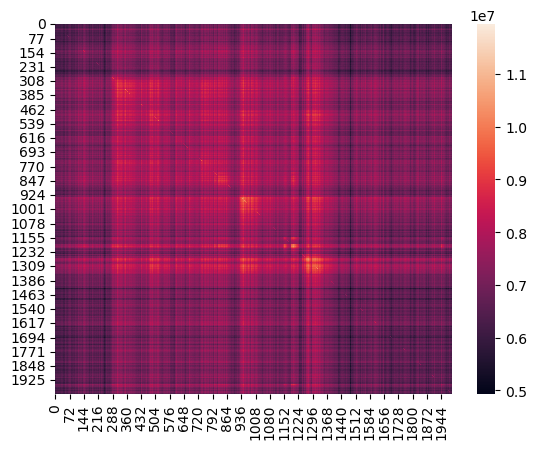

In [17]:
COV = similarity_matrix(P[0,:,:])
print (COV)
sns.heatmap(COV[:, :])
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/original_cov_{fig_label}.png')

In [18]:
Pc = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
for lag in range(0,n_lags+1):
    Pc[lag,:,:] = centered_matrix(P[lag,:,:])

eigenvectors.shape = (756, 756)
eigenvectors.shape = (756, 756)
eigenvectors.shape = (756, 756)
P.shape = (3, 756, 1998)
Pw.shape = (3, 756, 1998)
[[ 0.77338407  0.00994169  0.00425544 ...  0.00908644  0.01820596
   0.01072859]
 [ 0.00994169  0.83576855  0.06668548 ...  0.02868509  0.02023459
  -0.02395035]
 [ 0.00425544  0.06668548  0.85627371 ... -0.00639818 -0.04197048
  -0.00609478]
 ...
 [ 0.00908644  0.02868509 -0.00639818 ...  0.93032607 -0.00318604
   0.01825418]
 [ 0.01820596  0.02023459 -0.04197048 ... -0.00318604  0.66687339
   0.0053811 ]
 [ 0.01072859 -0.02395035 -0.00609478 ...  0.01825418  0.0053811
   0.83256139]]


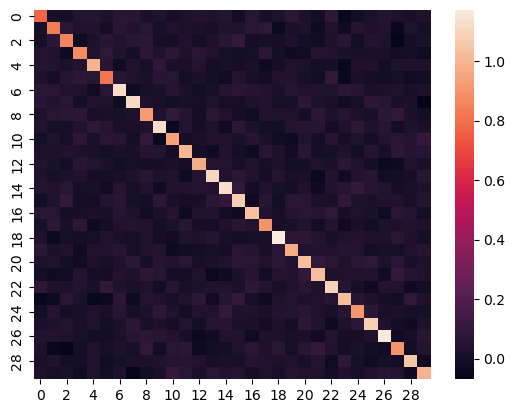

In [19]:
Pw = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
if use_eco_whitening:
    Pw = np.zeros((n_lags+1,k,n_time_steps-n_lags*lag_time))
for lag in range(0,n_lags+1):
    if use_centering:
        Pw[lag,:,:] = whitened_matrix(Pc[lag,:,:],Pc[0,:,:])
    else:
        if use_eco_whitening:
            Pw[lag,:,:] = eco_whitened_matrix(P[lag,:,:],P[lag,:,:],k)
        else:
            Pw[lag,:,:] = whitened_matrix(P[lag,:,:],P[0,:,:])
print (f"P.shape = {P.shape}")
print (f"Pw.shape = {Pw.shape}")

# verify that Pw is whitened data
COV = similarity_matrix(Pw[0,:,:])
print (COV)
sns.heatmap(COV[:30, :30])
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/whitened_PTP_{fig_label}.png')

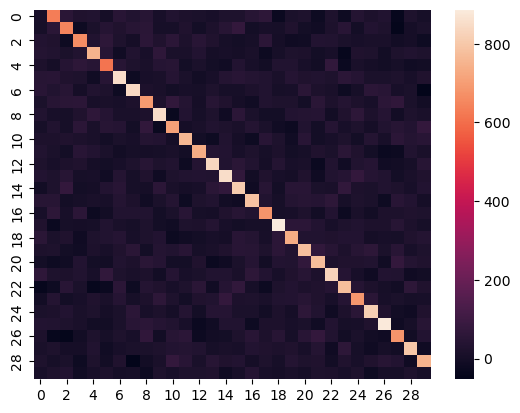

In [20]:
if n_lags>0:
    cross_correlation = Pw[1,:,:].T @ Pw[0,:,:]
    sns.heatmap(cross_correlation[:30, :30])
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/whitened_ZTZ_{fig_label}.png')

In [21]:
if use_whitening:
    if n_lags==0:
        Z = Pw[0].copy()
    if n_lags==1:
        Z = np.vstack((Pw[0], Pw[1]))
    if n_lags==2:
        Z = np.vstack((Pw[0], Pw[1], Pw[2]))
    if n_lags==3:
        Z = np.vstack((Pw[0], Pw[1], Pw[2], Pw[3]))
    if n_lags==4:
        Z = np.vstack((Pw[0], Pw[1], Pw[2], Pw[3], Pw[4]))
    if n_lags==5:
        Z = np.vstack((Pw[0], Pw[1], Pw[2], Pw[3], Pw[4], Pw[5]))
else:
    if n_lags==0:
        Z = P[0].copy()
    if n_lags==1:
        Z = np.vstack((P[0], P[1]))
    if n_lags==2:
        Z = np.vstack((P[0], P[1], P[2]))
    if n_lags==3:
        Z = np.vstack((P[0], P[1], P[2], P[3]))
    if n_lags==4:
        Z = np.vstack((P[0], P[1], P[2], P[3], P[4]))
    if n_lags==5:
        Z = np.vstack((P[0], P[1], P[2], P[3], P[4], P[5]))
    
ZTZ = similarity_matrix(Z)
print (f"ZTZ.shape = {ZTZ.shape}")
if denoise_diagonal:
    # diagonal_mean = np.mean(np.diag(ZTZ))
    # ZTZ = ZTZ - np.identity(ZTZ.shape[0]) * diagonal_mean
    # ZTZ = ZTZ.clip(0)
    np.fill_diagonal(ZTZ, 0.)

ZTZ.shape = (1998, 1998)


eigenvectors.shape = (2268, 2268)


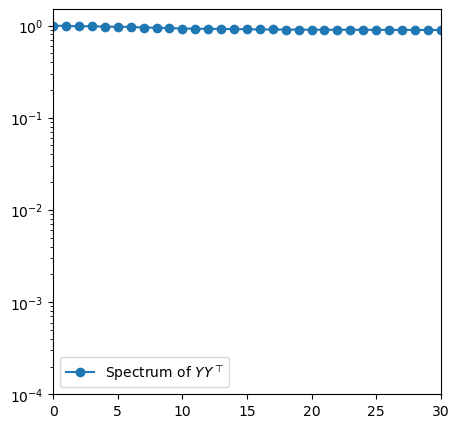

In [22]:
ZZT = covariance_matrix(Z)
S_ZZT, U_ZZT = eigen_decomposition(ZZT)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(S_ZZT[:] / S_ZZT.max(),'o-', label="Spectrum of $YY^{\\top}$")
ax.legend()
ax.set_yscale('log')
plt.ylim(0.0001, 1.5)
plt.xlim(0, 30)
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/YYT_spectrum_src{src}_{fig_label}.png')
plt.show()

In [23]:
S, U = eigen_decomposition(Pw[0].T @ Pw[0])
if n_lags>0:
    S_lag, U_lag = eigen_decomposition(ZTZ)

eigenvectors.shape = (1998, 1998)
eigenvectors.shape = (1998, 1998)


U.shape = (1998, 1998)


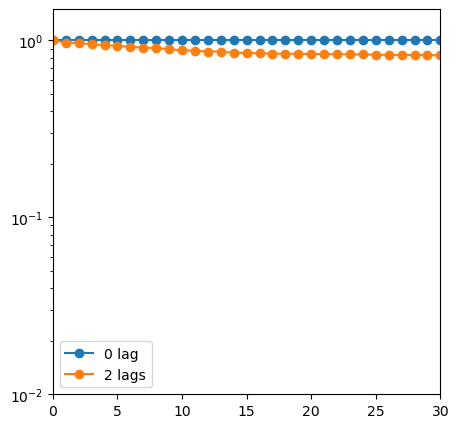

In [24]:
print (f"U.shape = {U.shape}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(S[:] / S.max(),'o-', label="0 lag")
if n_lags>0:
    ax.plot(S_lag[:] / S_lag.max(),'o-', label=f"{n_lags} lags")
ax.legend()
ax.set_yscale('log')
plt.ylim(0.01, 1.5)
plt.xlim(0, 30)
plt.show()

In [25]:
from sklearn.utils.extmath import randomized_svd
def nnsvd(X_init, k, eps: float = 1e-6):
    U, S, V = randomized_svd(X_init, n_components=k)
    W = np.zeros_like(U)
    H = np.zeros_like(V)
    
    # The leading singular triplet is non-negative
    # so it can be used as is for initialization.
    W[:, 0] = np.sqrt(S[0]) * np.abs(U[:, 0])
    H[0, :] = np.sqrt(S[0]) * np.abs(V[0, :])
    
    for j in range(1, k):
        x, y = U[:, j], V[j, :]
    
        # extract positive and negative parts of column vectors
        x_p, y_p = np.maximum(x, 0), np.maximum(y, 0)
        x_n, y_n = np.abs(np.minimum(x, 0)), np.abs(np.minimum(y, 0))
    
        # and their norms
        x_p_nrm, y_p_nrm = np.linalg.norm(x_p, ord=2), np.linalg.norm(y_p, ord=2)
        x_n_nrm, y_n_nrm = np.linalg.norm(x_n, ord=2), np.linalg.norm(y_n, ord=2)
    
        m_p, m_n = x_p_nrm * y_p_nrm, x_n_nrm * y_n_nrm
    
        # choose update
        if m_p > m_n:
            u = x_p / x_p_nrm
            v = y_p / y_p_nrm
            sigma = m_p
        else:
            u = x_n / x_n_nrm
            v = y_n / y_n_nrm
            sigma = m_n
    
        lbd = np.sqrt(S[j] * sigma)
        W[:, j] = lbd * u
        H[j, :] = lbd * v
    
    W[W < eps] = 0
    H[H < eps] = 0
    
    return W, H


In [26]:
from tqdm.notebook import tqdm

eta = 0.1
error_stop = 1e-4
n_iterations = 5_000
error_log = np.zeros(n_iterations)

# S, U = eigen_decomposition(ZTZ)
# Uk = U[:,:k]
# Sk = np.diag(np.sqrt(S[:k]))
# H_init = np.abs(Uk @ Sk)

# H_init, _ = nnsvd(Z,k)
H_init = 2 * np.sqrt(np.mean(np.mean(ZTZ) / k)) * np.random.rand(ZTZ.shape[0], k)
print (f"H_init.shape = {H_init.shape}")

H = H_init.T

T = H.shape[1]

epsilon = 1e-10
epsilon_mtx = np.ones_like(H@H.T@H) * epsilon

# beta = 0.001
# beta = 0.01
# beta = 0.1
beta = 1.0
# beta = 10.0
# beta = 100.
# beta = 1000.

for n_iter in tqdm(range(n_iterations)):
    H_old = H.copy()

    # gamma = H_old @ ZTZ / (beta * (H_old @ H_old.T @ H_old / float(T)) + epsilon_mtx)
    # H = H_old * (1-eta) + eta * H_old * gamma

    H = H_old + eta * (H_old @ ZTZ - beta * H_old @ H_old.T @ H_old / float(T))
    H = H.clip(0)  

    er = np.divide(np.abs(H - H_old), np.abs(H_old + epsilon)).mean() / eta
    error_log[n_iter] = er
    # print (f"er = {er}")

    if er < error_stop:
        break

H_init.shape = (1998, 9)


  0%|          | 0/5000 [00:00<?, ?it/s]

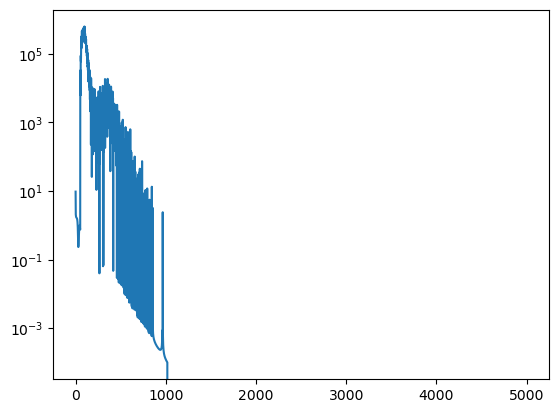

In [27]:
plt.plot(error_log)
plt.yscale('log')
# plt.xscale('log')
plt.show()

[[0.         0.0178185  0.01988508 ... 0.00774208 0.00196236 0.00188865]
 [0.0178185  0.         0.02833418 ... 0.01175698 0.04312397 0.01577834]
 [0.01988508 0.02833418 0.         ... 0.01921911 0.00824777 0.01121259]
 ...
 [0.00774208 0.01175698 0.01921911 ... 0.         0.01873652 0.0193124 ]
 [0.00196236 0.04312397 0.00824777 ... 0.01873652 0.         0.06341197]
 [0.00188865 0.01577834 0.01121259 ... 0.0193124  0.06341197 0.        ]]


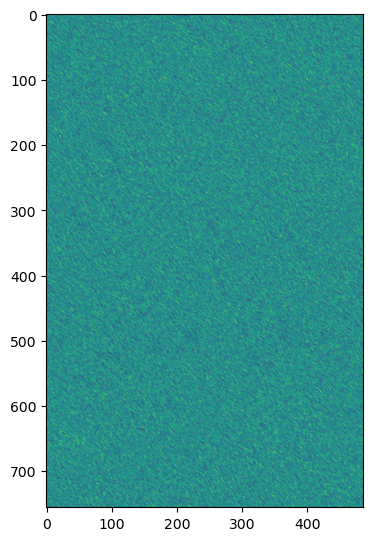

In [28]:
print (ZTZ)
# iw = fpl.ImageWidget(ZTZ, cmap="viridis", histogram_widget=False)
# iw.show()

fig, ax = plt.subplots(1, 1, figsize=(6.4, 6.4))
ax.imshow(ZTZ[:n_pixels,n_lags*n_pixels:,])
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/ZTZ_{fig_label}.png')
plt.show()

[[0.49245848 0.38241597 0.29347848 ... 0.14853061 0.17932247 0.2961139 ]
 [0.38241597 0.33588306 0.24488875 ... 0.1335393  0.08949262 0.10554223]
 [0.29347848 0.24488875 0.18498938 ... 0.09156897 0.08937112 0.12940647]
 ...
 [0.14853061 0.1335393  0.09156897 ... 0.26091325 0.22611499 0.36284978]
 [0.17932247 0.08949262 0.08937112 ... 0.22611499 0.45748251 0.76910958]
 [0.2961139  0.10554223 0.12940647 ... 0.36284978 0.76910958 1.45532485]]


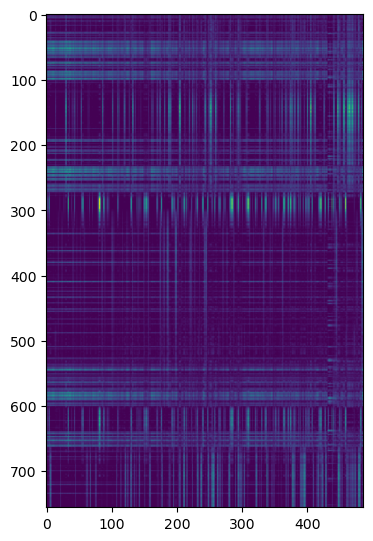

In [29]:
HTH = similarity_matrix(H)
print (HTH)

fig, ax = plt.subplots(1, 1, figsize=(6.4, 6.4))
ax.imshow(np.abs(HTH[:n_pixels,n_lags*n_pixels:]))
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/HHT_{fig_label}.png')
plt.show()

In [30]:
H_sum = np.zeros((k,n_time_steps-n_lags*lag_time))
print (f"H_sum.shape = {H_sum.shape}")
print (f"H.shape = {H.shape}")
H_sum += H

S_solved = H_sum
# A_concatenated = Z @ H_sum.T
if use_eco_whitening:
    A_concatenated = P[0] @ H_sum.T
else:
    A_concatenated = Z @ H_sum.T
print (f"A_concatenated.shape = {A_concatenated.shape}")

H_sum.shape = (9, 1998)
H.shape = (9, 1998)
A_concatenated.shape = (2268, 9)


In [31]:
A_solved = np.zeros((n_pixels,k))
if n_lags==0:
    A_solved += A_concatenated
else:
    for lag in range(0,n_lags+1):
        A_solved[:,:] += A_concatenated[lag*n_pixels:(lag+1)*n_pixels,:] / float(n_lags+1)

S_solved = S_solved.clip(0)
A_solved = A_solved.clip(0)

image_array = []
for entry in range(0,k):

    snapshot = unvec.transform(A_solved[:,entry])
    image_array += [snapshot]

# F_rgba = spatial_to_rgba(np.array(image_array), 90)
# for c in F_rgba:
#     plt.imshow(c, alpha=0.3)
# plt.show()

# fig, ax = plt.subplots(k, 1, figsize=(6.4, k * 4.8))
# for row in range(0,k):
#     ax[row].imshow(image_array[row])
# plt.show()

In [32]:
from sklearn.metrics.pairwise import cosine_similarity

S_vec = vectorizer.fit_transform(source_footprints).T
print (f"S_vec.shape = {S_vec.shape}")

if simulation:
    cluster_matching = []
    selected_cluster = []
    for src in range(0,n_sources):
        max_corr = 0.
        pair_indices = []
        for cluster in range(0,k):
            if cluster in selected_cluster: 
                continue
            corr = S_vec[src] @ A_solved[:,cluster].T / np.sqrt(A_solved[:,cluster] @ A_solved[:,cluster].T * S_vec[src] @ S_vec[src].T)
            if corr > max_corr:
                max_corr = corr
                pair_indices = [src, cluster]
        cluster_matching += [pair_indices]
        selected_cluster += [pair_indices[1]]
    print (f"cluster_matching = {cluster_matching}")

S_vec.shape = (15, 144)


(9, 1998)
(756, 2000)
(15, 2000)
(15, 2000)


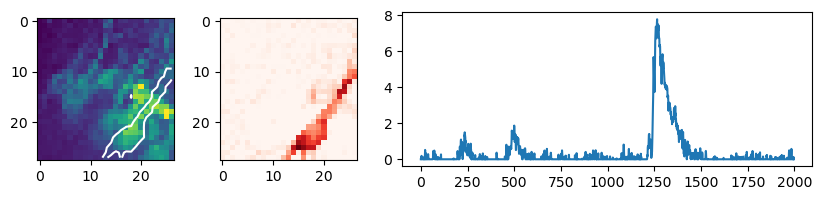

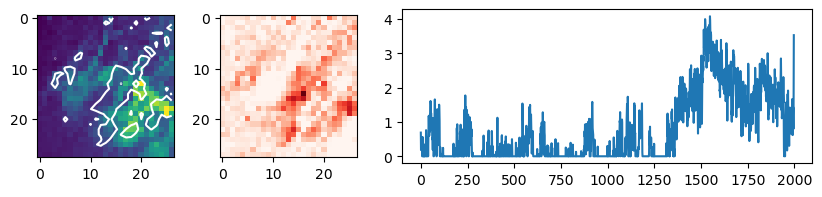

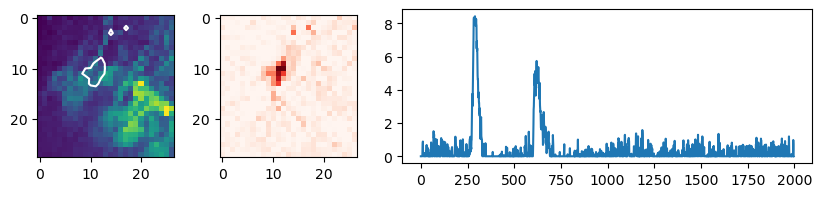

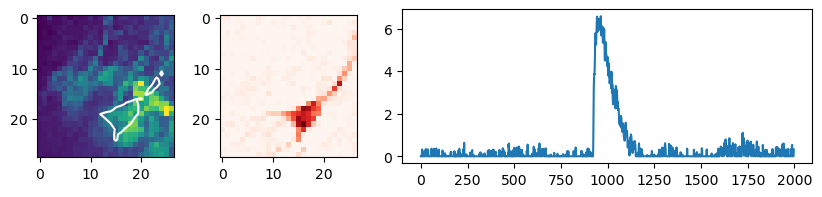

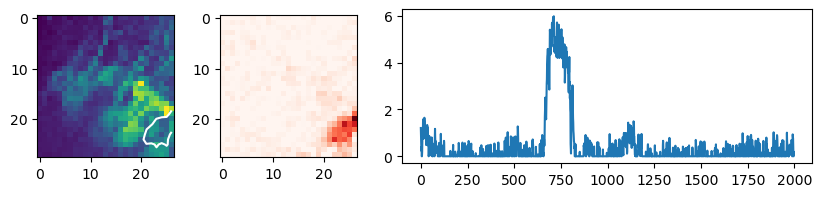

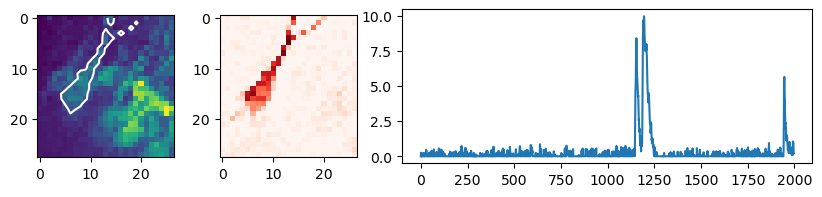

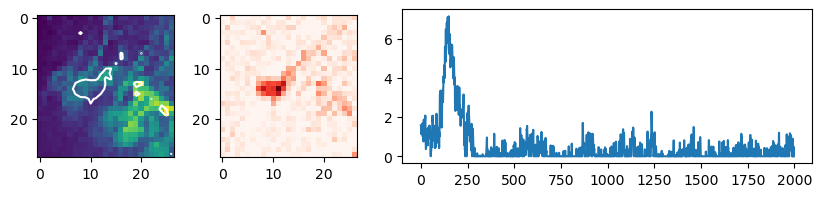

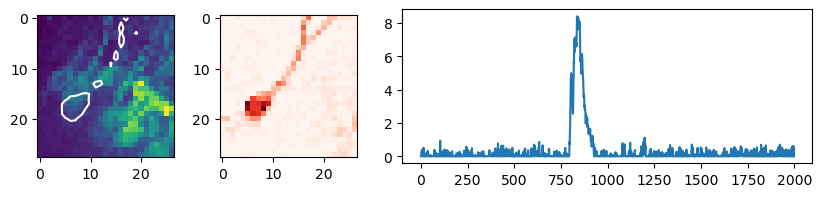

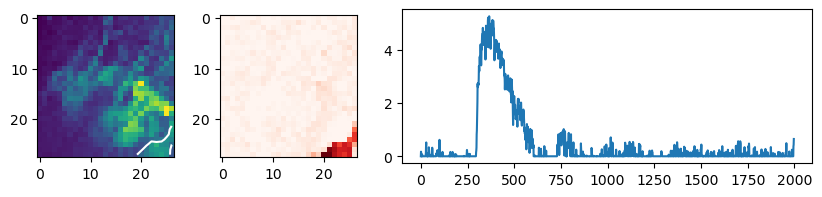

In [33]:
print (H_sum.shape)
print (X.shape)
print (traces.shape)

S_sorted = np.zeros_like(traces)
print (S_sorted.shape)

if simulation:
    for src in range(0,n_sources):
        truth_norm = np.sum(traces[src])
        cluster = cluster_matching[src][1]
        reco_norm = np.sum(S_solved[cluster])
        S_solved[cluster] = S_solved[cluster] * truth_norm / reco_norm
        S_sorted[src,n_lags*lag_time:] = S_solved[cluster]

matching_score = 0.
truth_score = 0.
if simulation:
    reco_levels = [0.60]
    for src in range(0,n_sources):
        truth_levels = [0.60]
        reco_levels = [0.60*np.max(image_array[cluster])]
        fig, ax = plt.subplots(1, 3, figsize=(10, 3), gridspec_kw={'width_ratios': [1, 1, 3]})
        cluster = cluster_matching[src][1]
        ax[0].imshow(movie.mean(axis=0))
        ax[0].contour(source_footprints[src], levels=truth_levels, colors='r')
        ax[0].contour(image_array[cluster] / np.max(image_array[cluster]), levels=reco_levels, colors='w')
        ax[1].imshow(image_array[cluster])
        ax[2].plot(S_solved[cluster], label="reconstruction")
        ax[2].plot(traces[src] + 1.1*np.max(S_solved[cluster]), label="truth")
        # ax[2].legend()
        plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/source_extract_src{src}_{fig_label}.png')
        plt.show()

        matching_score += S_solved[cluster].T @ traces[src,n_lags*lag_time:]
        truth_score += np.sqrt(traces[src,n_lags*lag_time:].T @ traces[src,n_lags*lag_time:] * S_solved[cluster].T @ S_solved[cluster])

    print (f"matching_score / truth_score = {matching_score / truth_score}")
else:
    for src in range(0,k):
        reco_levels = [0.30*np.max(image_array[src])]
        fig, ax = plt.subplots(1, 3, figsize=(10, 2), gridspec_kw={'width_ratios': [1, 1, 3]})
        ax[0].imshow(movie.mean(axis=0))
        ax[0].contour(image_array[src], levels=reco_levels, colors='w')
        ax[1].imshow(image_array[src], cmap="Reds")
        ax[2].plot(S_solved[src])
        plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/source_extract_src{src}_{fig_label}.png')
        plt.show()



In [34]:
if simulation:
    sns.heatmap(cosine_similarity(S_sorted, traces))
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/CCA_cos_similarity_noise_multiple.png')